# Week6_ex1_analysis — Single line-to-ground faults in `calc_sc`: generator grounding and IEC factors

Deep dive. The classical method (PowerWorld, textbook) drives the series connection of the three sequence networks with the pre-fault voltage:

$$I_F = 3 I_0 = \frac{3\,V_F}{Z_1 + Z_2 + Z_0}, \qquad V_F = 1.05\ \text{pu}$$

pandapower's `calc_sc(fault="1ph")` follows IEC 60909 with the same circuit, the voltage factor $c_{max} = 1.1$ and the correction factors $K_G$ (generators) and $K_T$ (network transformers):

$$I''_{k1} = \frac{\sqrt{3}\,c\,U_n}{|Z_1 + Z_2 + Z_0|}, \qquad K_T = 0.95\,\frac{c_{max}}{1 + 0.6\,x_T}$$

On the Example 10.8 system, `calc_sc` returns zero fault current at both generator buses. This notebook finds out why, tests a workaround, and checks whether the IEC result can still be treated as the conservative one.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.shortcircuit as sc
from scipy.linalg import LinAlgWarning
from case5 import (S_BASE, V_PREFAULT, BUS_KV, BUSES, GENS, TRAFOS, LINES, C_MAX, k_t,
                   sequence_ybus, build_sc_case)

# 1. calc_sc triggers a pandas downcasting FutureWarning inside pandapower's branch builder;
#    it does not affect the results and its message prints the local install path
warnings.filterwarnings("ignore", category=FutureWarning)

Z_BASE = pd.Series({b: kv ** 2 / S_BASE for b, kv in BUS_KV.items()})
I_BASE = pd.Series({b: S_BASE / (np.sqrt(3) * kv) for b, kv in BUS_KV.items()})

def run_1ph(gen_grounding):
    # 2. calc_sc SLG at every bus; returns Z1, Z0 [pu] and |I''k1| [pu] on each bus's own base
    net = build_sc_case(gen_grounding)
    pp.runpp(net, numba=False)
    # 3. A grounding bank's empty delta-side bus has no zero-sequence connection, so scipy
    #    flags the zero-sequence Ybus as ill-conditioned (and prints its install path). That
    #    row never reaches the real buses: Hypothesis 3 matches a hand calculation to 1e-6
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=LinAlgWarning)
        sc.calc_sc(net, fault="1ph", case="max")
    r = net.res_bus_sc.loc[BUSES]
    return pd.DataFrame({"Z1 [pu]": r.xk_ohm / Z_BASE, "Z0 [pu]": r.xk0_ohm / Z_BASE,
                         "I [pu]": r.ikss_ka / I_BASE})

# 4. Classical reference: sequence Zbus matrices with V_F = 1.05 pu (the PowerWorld method)
Z = {s: np.linalg.inv(sequence_ybus(s)) for s in (1, 2, 0)}
z1, z0 = (pd.Series(np.abs(np.diag(Z[s])), index=BUSES) for s in (1, 0))
i_classical = 3 * V_PREFAULT / (2 * z1 + z0)

default = run_1ph("none")
meas = pd.DataFrame({"Classical I_SLG [pu]": i_classical, "calc_sc I_SLG [pu]": default["I [pu]"],
                     "Classical Z0 [pu]": z0, "calc_sc Z0 [pu]": default["Z0 [pu]"]})
meas.index.name = "Faulted bus"
meas.round(4)

,Classical I_SLG [pu],calc_sc I_SLG [pu],Classical Z0 [pu],calc_sc Z0 [pu]
Faulted bus,,,,
1,46.0217,0.0000,0.0125,100000.0000
2,14.1355,14.5960,0.1089,0.1092
3,64.3034,0.0000,0.0125,100000.0000
4,56.0731,55.4015,0.0089,0.0093
5,42.1650,42.2144,0.0158,0.0162


## Hypothesis 1

On the 345 kV buses the generators sit behind delta windings, so their zero-sequence data cannot matter there. `calc_sc` should then equal the hand-built zero-sequence Zbus once each network transformer's $X_0$ is multiplied by the same $K_T$ that IEC applies to $X_1$.

In [2]:
def zbus_diag(seq, kt=False, kg=False, cos_phi=0.85):
    # 5. Hand-built sequence Zbus diagonal with optional IEC corrections
    idx = {b: i for i, b in enumerate(BUSES)}
    y = np.zeros((5, 5), complex)
    def stamp(f, t, x):
        a = 1 / (1j * x)
        y[idx[f], idx[f]] += a
        if t is not None:
            y[idx[t], idx[t]] += a
            y[idx[f], idx[t]] -= a
            y[idx[t], idx[f]] -= a
    sin_phi = np.sqrt(1 - cos_phi ** 2)
    for b, x1, x2, x0, xn in GENS:
        stamp(b, None, x0 + 3 * xn if seq == 0 else x1 * (C_MAX / (1 + x1 * sin_phi) if kg else 1))
    for w, d, x, x0 in TRAFOS:
        k = k_t(x) if kt else 1
        if seq == 0:
            stamp(w, None, x0 * k)
        else:
            stamp(w, d, x * k)
    for f, t, x, x0 in LINES:
        stamp(f, t, x0 if seq == 0 else x)
    return pd.Series(np.abs(np.diag(np.linalg.inv(y))), index=BUSES)

# 6. Network buses only: generator buses are tested in Hypothesis 2
net_buses = [2, 4, 5]
h1 = pd.DataFrame({"Classical Z0 [pu]": z0[net_buses],
                   "Hand Z0, X0 x K_T [pu]": zbus_diag(0, kt=True)[net_buses],
                   "calc_sc Z0 [pu]": default.loc[net_buses, "Z0 [pu]"]})
h1["Diff [pu]"] = (h1["Hand Z0, X0 x K_T [pu]"] - h1["calc_sc Z0 [pu]"]).abs()
h1["calc_sc / classical"] = h1["calc_sc Z0 [pu]"] / h1["Classical Z0 [pu]"]
assert h1["Diff [pu]"].max() < 1e-6
h1.round(6)

,Classical Z0 [pu],"Hand Z0, X0 x K_T [pu]",calc_sc Z0 [pu],Diff [pu],calc_sc / classical
2,0.108939,0.109219,0.109219,0.0,1.002565
4,0.008939,0.009256,0.009256,0.0,1.035386
5,0.015758,0.016178,0.016178,0.0,1.026675


**Verdict: accepted.** With $K_T$ applied to the transformer $X_0$ (1.033 for T 5-1, 1.039 for T 4-3) the hand calculation matches `calc_sc` to better than $10^{-6}$ pu. The zero-sequence impedance grows by 0.3% at bus 2 (mostly line reactance) and by 3.5% at bus 4 (mostly transformer reactance). The network side of the zero-sequence model is correct.

## Hypothesis 2

`calc_sc` ignores the generator zero-sequence path. pandapower has no input field for a generator's $X_0$ or neutral grounding impedance, and its zero-sequence builder (`_add_gen_sc_impedance_zero` in `pd2ppc_zero.py`) adds only a fixed $1/(1000 + j1000)\ \Omega$ at every generator bus, i.e. every machine is treated as ungrounded. Buses 1 and 3 are then cut off from ground in the zero sequence and the SLG current should vanish.

In [3]:
# 7. The only zero-sequence paths at buses 1 and 3 in the textbook model are the generators
h2 = pd.DataFrame({"X0 + 3Xn [pu]": [x0 + 3 * xn for _, _, _, x0, xn in GENS],
                   "calc_sc Z0 [pu]": default.loc[[b for b, *_ in GENS], "Z0 [pu]"].values,
                   "calc_sc I_SLG [kA]": (default.loc[[b for b, *_ in GENS], "I [pu]"]
                                         * I_BASE[[b for b, *_ in GENS]]).values,
                   "Classical I_SLG [kA]": (i_classical * I_BASE)[[b for b, *_ in GENS]].values},
                  index=pd.Index([f"Bus {b}" for b, *_ in GENS], name="Generator bus"))
assert (h2["calc_sc I_SLG [kA]"] < 1e-2).all()
h2.round(4)

,X0 + 3Xn [pu],calc_sc Z0 [pu],calc_sc I_SLG [kA],Classical I_SLG [kA]
Generator bus,,,,
Bus 1,0.0125,100000.0,0.0001,177.1377
Bus 3,0.0125,100000.0,0.0001,247.5041


**Verdict: accepted.** `calc_sc` reports $Z_0 = 10^5$ pu (open circuit) and essentially zero current at both generator buses, against 177 kA and 248 kA by the classical method. Nothing in the input can change this: the generator's grounding is simply not part of the model.

This is not always wrong in practice. A unit-connected generator behind a delta-wye step-up transformer is normally grounded through a high resistance, and its terminal earth-fault current is a few amperes to tens of amperes — a stator earth-fault protection problem, not a breaker-duty one. The real risk is a **grounded generator connected directly to a network bus**: its zero-sequence contribution disappears and the SLG current at that bus is underestimated.

## Hypothesis 3

A grounding bank restores the missing path: a YNd transformer from the generator bus to an empty bus, with $v_{k0} = 100\,(X_0 + 3X_n)$. With nothing on the delta side it carries no positive- or negative-sequence current, while in the zero sequence it is exactly an $X_0 + 3X_n$ path to ground. Since `calc_sc` treats it as a network transformer, its $X_0$ is multiplied by its own $K_T$; dividing $v_{k0}$ by that $K_T$ should bring the path back to $X_0 + 3X_n$ and make `calc_sc` equal the hand-built IEC calculation (Hypothesis 1 corrections, generator $X_0 + 3X_n$ uncorrected).

In [4]:
# 8. Grounding bank as entered, and with vk0 divided by the bank's own K_T
raw, comp = run_1ph("trafo"), run_1ph("compensated")

# 9. Hand IEC reference: c = 1.1, K_G on generator X1, K_T on network transformers
i_hand = 3 * C_MAX / (2 * zbus_diag(1, kt=True, kg=True) + zbus_diag(0, kt=True))

h3 = pd.DataFrame({"Z0 default [pu]": default["Z0 [pu]"], "Z0 bank [pu]": raw["Z0 [pu]"],
                   "Z0 bank, compensated [pu]": comp["Z0 [pu]"],
                   "Z1 change [pu]": (comp["Z1 [pu]"] - default["Z1 [pu]"]).abs(),
                   "I bank, compensated [pu]": comp["I [pu]"], "Hand IEC I [pu]": i_hand})
h3["I diff [pu]"] = (h3["I bank, compensated [pu]"] - h3["Hand IEC I [pu]"]).abs()
h3.index.name = "Faulted bus"
assert h3["Z1 change [pu]"].max() < 1e-9 and h3["I diff [pu]"].max() < 1e-6
assert np.allclose(raw.loc[[1, 3], "Z0 [pu]"], [k_t(0.0125) * 0.0125] * 2)
h3.round(6)

,Z0 default [pu],Z0 bank [pu],"Z0 bank, compensated [pu]",Z1 change [pu],"I bank, compensated [pu]",Hand IEC I [pu],I diff [pu]
Faulted bus,,,,,,,
1,100000.000000,0.012965,0.012500,0.0,45.908299,45.908298,0.000000
2,0.109219,0.109219,0.109219,0.0,14.595953,14.595953,0.000000
3,100000.000000,0.012965,0.012500,0.0,63.621812,63.621811,0.000001
4,0.009256,0.009256,0.009256,0.0,55.401516,55.401516,0.000000
5,0.016178,0.016178,0.016178,0.0,42.214428,42.214428,0.000000


**Verdict: accepted.** The bank leaves $Z_1$ untouched and does not change $Z_0$ on the 345 kV buses. As entered, the generator buses get $Z_0 = K_T \cdot 0.0125 = 0.01297$ pu ($K_T = 1.037$); with the compensated $v_{k0}$ they get exactly 0.0125 pu, and the SLG currents match the hand IEC calculation to better than $10^{-6}$ pu. The compensated form is the one to use: it keeps the generator path at its data value, and of the two it gives the higher current.

## Hypothesis 4

In Week 5 the IEC default (`calc_sc`, max case) was adopted for breaker duty because it came out above PowerWorld on the 37-bus system. If that carries over, `calc_sc` with the compensated grounding bank should give an SLG current at least as high as the classical method on every bus.

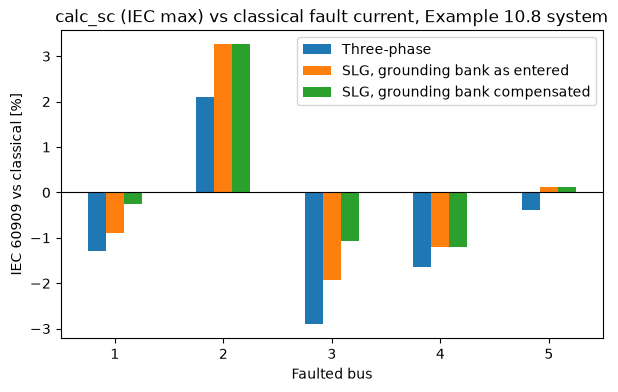

,Classical SLG [pu],IEC SLG [pu],SLG dev [%],"SLG dev, bank as entered [%]",3ph dev [%]
Faulted bus,,,,,
1,46.022,45.908,-0.246,-0.888,-1.301
2,14.135,14.596,3.257,3.257,2.102
3,64.303,63.622,-1.060,-1.940,-2.909
4,56.073,55.402,-1.198,-1.198,-1.635
5,42.165,42.214,0.117,0.117,-0.385


In [5]:
# 10. Deviation of the IEC result from the classical method, SLG and three-phase
i3_classical = V_PREFAULT / z1
i3_iec = C_MAX / zbus_diag(1, kt=True, kg=True)
h4 = pd.DataFrame({"Classical SLG [pu]": i_classical, "IEC SLG [pu]": comp["I [pu]"],
                   "SLG dev [%]": (comp["I [pu]"] / i_classical - 1) * 100,
                   "SLG dev, bank as entered [%]": (raw["I [pu]"] / i_classical - 1) * 100,
                   "3ph dev [%]": (i3_iec / i3_classical - 1) * 100})
h4.index.name = "Faulted bus"

ax = h4[["3ph dev [%]", "SLG dev, bank as entered [%]", "SLG dev [%]"]].plot.bar(
    figsize=(7, 4), rot=0)
ax.legend(["Three-phase", "SLG, grounding bank as entered", "SLG, grounding bank compensated"])
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Faulted bus")
ax.set_ylabel("IEC 60909 vs classical [%]")
ax.set_title("calc_sc (IEC max) vs classical fault current, Example 10.8 system")
plt.savefig("Images/Week6_ex1_slg_iec_vs_classical.png", dpi=150, bbox_inches="tight")
plt.show()
h4.round(3)

**Verdict: rejected.** The IEC SLG current is 0.3–1.2% *below* the classical value at buses 1, 3 and 4, and above it only at buses 2 (+3.3%) and 5 (+0.1%). The pattern follows the three-phase case (−2.9% to +2.1%): $K_G$ pushes the generator-side buses down, and the classical pre-fault voltage of 1.05 pu is not much below $c_{max} = 1.1$. At the generator-side buses the SLG deviations are smaller than the three-phase ones because $Z_0$ carries no $K_G$; at bus 2, whose $Z_0$ is mostly line reactance and barely corrected, more of the +4.76% voltage factor survives. The sign matches the three-phase case at four of five buses. The conservatism found on the 37-bus system is a property of that system, not of `calc_sc`.

## Final conclusion

- The zero-sequence network model in `calc_sc` is correct for lines and YNd transformers; it only adds $K_T$ to the transformer $X_0$, as for $X_1$.
- `calc_sc` has no generator zero-sequence model: every generator is ungrounded. On this system that gives **0 kA** at both generator buses instead of 177 kA and 248 kA.
- A YNd grounding bank to an empty bus with $v_{k0} = 100\,(X_0 + 3X_n)/K_T$ restores the path exactly, without touching the positive sequence.
- Even with the bank, the IEC result is not always above the classical one: here it is up to 1.2% lower for SLG and 2.9% lower for three-phase faults.

**Rules for the project (SLG faults):**
1. Generator behind a delta winding with high-resistance grounding: `calc_sc` is fine on the network buses; terminal earth faults belong to generator protection and are left out of breaker duty, stated in the report.
2. Grounded generator connected directly to a network bus: add a compensated grounding bank for every such machine, otherwise `calc_sc` underestimates the SLG current at that bus.
3. Check every system against a hand-built sequence Zbus with the actual pre-fault voltages, and take the larger of the two for breaker duty. Do not assume `calc_sc` is conservative.